# Callable Bond Pricer: European, Bermudan and American Calls under Hull-White 1F

A **callable bond** is a fixed-rate bond that the issuer may redeem early at the call price $K(t)$ plus accrued
interest $AI(t)$. The bondholder is short a call on the bond, so

$$
\text{callable bond} = \text{straight bond} - \text{issuer call option}.
$$

| Style | The issuer can call | Equivalent option on the straight bond |
|---|---|---|
| European | on one date only (end of the call protection) | European receiver swaption (Jamshidian) |
| Bermudan | on every coupon date after the call protection (or any schedule) | Bermudan receiver swaption |
| American | at any time after the call protection, until maturity | continuously exercisable option |

**What this notebook delivers.** A full pricer, from a term sheet in **calendar dates** to prices and risk:

1. term sheet with a seasoned schedule, accrued interest, clean and dirty prices (`DatedCallableBond`);
2. **three independent numerical methods** under the same model, with the same interface:
   Crank-Nicolson PDE, Hull-White trinomial tree, Monte Carlo + Longstaff-Schwartz;
3. validation against closed forms (straight bond, Jamshidian) and between methods;
4. market measures: yield to maturity, to each call date, **yield to worst**, Z-spread, **OAS**;
5. risk: effective duration and convexity, DV01, key-rate durations, vega, CS01;
6. exercise analysis: critical short rate $r^*(t)$, call probabilities, expected life;
7. model risk (mean reversion, volatility) and term sheet variants (step-down call price, call frequency).

**Model.** Hull-White one factor, $r(t) = x(t) + \alpha(t)$, $dx = -a x\,dt + \sigma\, dW$, fitted exactly to the
risk-free curve and calibrated to co-terminal swaptions. Issuer default is a reduced-form event with a
deterministic intensity $\lambda(t)$ bootstrapped from CDS spreads and recovery $R$ of par. The bond value
$V(t,x)$ solves

$$
\partial_t V - a x\, \partial_x V + \tfrac12 \sigma^2 \partial_{xx} V - \big(x + \alpha(t) + \lambda(t)\big) V + \lambda(t) R N = 0,
$$

with $V = N$ at maturity, coupons added on payment dates and, on every call date, the issuer's choice
$V \leftarrow \min\big(V,\ K(t) + AI(t)\big)$. **The three styles only differ by the set of dates where this min is
applied.**

**Code reused.** `Fixed_Income_Models` (yield curve, `HullWhite`: closed forms, exact simulation, calibration),
`Products/rate_products.py` and `rates_market.py` (swaptions, vol grid). Everything specific to callable bonds
is in `callable_bond_pricer.py`: credit curve, product and dated term sheet, PDE solver, trinomial tree,
Longstaff-Schwartz pricer, closed forms, OAS, effective risk, yield measures, key-rate durations and the pricing
report.

> **What is real and what is assumed.** The risk-free curve is the **ECB euro area AAA government curve** of the
> last date in `Data/EUR` (market data). Swaption volatilities are the **illustrative** EUR grid of
> `Products/rates_market.py`; the issuer CDS spreads and the term sheet are **illustrative** (no specific issuer).

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models
sys.path.append(os.path.abspath(".."))                       # Produits : rate_products.py, rates_market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

from Fixed_Income_Models import HullWhite, YieldCurve, RatePricer
from rate_products import Swaption
from rates_market import illustrative_swaption_vols
from callable_bond_pricer import (DatedCallableBond, CallableBondPDE, CallableBondTree, CallableBondLSM, CreditCurve,
                                  EXERCISE_STYLES, straight_bond_value, european_callable_zero_recovery,
                                  option_adjusted_spread, effective_risk, yield_table, key_rate_durations,
                                  pricing_report)

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")

# Chart style : fixed categorical order, recessive grid and axes, 2px lines
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
STYLE_COLOR = {"straight": MUTED, "european": COLORS[0], "bermudan": COLORS[1], "american": COLORS[2]}
METHOD_COLOR = {"PDE": COLORS[0], "tree": COLORS[1], "LSM": COLORS[2]}

## 1. Market data

### 1.1 Risk-free curve
Spot rates of the ECB AAA curve (continuously compounded, 3 months to 30 years), monotone convex interpolation.

Valuation date 2026-10-05 | YieldCurve(name='ECB AAA 2026-10-05', method='monotone_convex', pillars=18 from 0.25y to 30y)


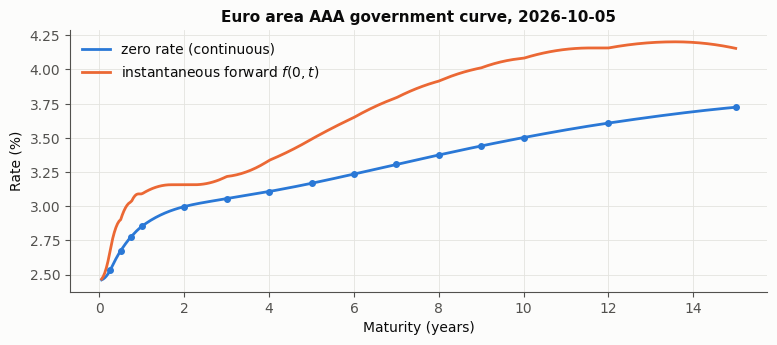

In [2]:
ecb = pd.read_csv(os.path.join("..", "..", "Data", "EUR", "ECB_AAA_YieldCurve.csv"), parse_dates=["Date"]).dropna()
row = ecb.iloc[-1]
VALUATION = row["Date"]
pillars = [c for c in ecb.columns if c.startswith("SR_")]
tenor = lambda c: float(c[3:-1]) / 12 if c.endswith("M") else float(c[3:-1])
curve = YieldCurve([tenor(c) for c in pillars], row[pillars].values.astype(float) / 100,
                   name=f"ECB AAA {VALUATION.date()}")
print(f"Valuation date {VALUATION.date()} | {curve}")

t = np.linspace(0.05, 15, 400)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, 100 * curve.zero_rate(t), label="zero rate (continuous)")
ax.plot(t, 100 * curve.instantaneous_forward(t), label="instantaneous forward $f(0,t)$")
ax.plot(curve.times[curve.times <= 15], 100 * curve.zero_rates[curve.times <= 15], "o", color=COLORS[0], ms=4)
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)")
ax.set_title(f"Euro area AAA government curve, {VALUATION.date()}"); ax.legend(); plt.show()

### 1.2 The term sheet

Illustrative BBB corporate bond, **seasoned**: issued 15/06/2024, maturity 15/06/2036, 4.75% annual coupon,
notional 100, **non-call until 15/06/2029**, callable at par. Model time is ACT/365F from the valuation date; coupons
are ACT/ACT ICMA (each regular period pays $N c / f$) and the accrued interest is pro rata of the period. Bond
prices are quoted **clean**; the model gives the **dirty** price (clean = dirty $-$ AI).

Column `callable`: E = European (first call date only), B = Bermudan (every coupon date from the first call to the
last but one), A = American (any time in the call period).

In [3]:
bond = DatedCallableBond(VALUATION, maturity_date="2036-06-15", coupon=0.0475, first_call_date="2029-06-15",
                         notional=100, frequency=1, issue_date="2024-06-15", name="illustrative BBB 4.75% 2036 NC2029")
bonds = {style: bond.with_exercise(style) for style in EXERCISE_STYLES}
print(bond)
print(f"Previous coupon {bond.previous_coupon_date.date()} | accrued interest at {VALUATION.date()} : "
      f"{bond.accrued_today:.4f} | maturity {bond.maturity:.4f}y | first call {bond.first_call:.4f}y")
bond.schedule_frame()

DatedCallableBond(bermudan, maturity 2036-06-15, coupon 4.75% x1, N = 100, call [2029-06-15: 100])
Previous coupon 2026-06-15 | accrued interest at 2026-10-05 : 1.4575 | maturity 9.7014y | first call 2.6959y


,t (ACT/365),coupon,call price,callable
date,,,,
2027-06-15,0.693151,4.75,NaN,
2028-06-15,1.69589,4.75,NaN,
2029-06-15,2.69589,4.75,100,EBA
2030-06-15,3.69589,4.75,100,BA
2031-06-15,4.69589,4.75,100,BA
2032-06-15,5.69863,4.75,100,BA
2033-06-15,6.69863,4.75,100,BA
2034-06-15,7.69863,4.75,100,BA
2035-06-15,8.69863,4.75,100,BA


### 1.3 Hull-White calibration

The call is an option on the bond's remaining cash flows, i.e. a receiver swaption on the **co-terminal** swaps
(exercise $T$, ending at the bond maturity). $(a, \sigma)$ are calibrated on the ATM co-terminal European receivers
$T \times (T_{\text{mat}} - T)$, $T = 1, \dots, 5$ (illustrative normal vols, residuals in bp of normal vol).

In [4]:
market = RatePricer(curve, swaption_vols=illustrative_swaption_vols())
swaptions = []
for expiry in [1, 2, 3, 4, 5]:
    atm = market.par_rate(Swaption(expiry, bond.maturity - expiry, 0.0, payer=False, notional=100).underlying())
    swaptions.append(Swaption(expiry, bond.maturity - expiry, atm, payer=False, notional=100))

hw = HullWhite(curve)
calibration = hw.calibrate(market, swaptions)
print(hw, "|", {k: round(v, 3) for k, v in calibration.items() if "bp" in k})
pd.DataFrame({"swaption": [f"{s.expiry:g}Y x {s.tenor:.2f}Y" for s in swaptions],
              "ATM strike (%)": [100 * s.strike for s in swaptions],
              "market vol (bp)": [1e4 * market.swaption_vol(s) for s in swaptions],
              "Hull-White vol (bp)": [1e4 * market.implied_swaption_vol(s, hw.price(s)) for s in swaptions]}
             ).set_index("swaption")

HullWhite(a=0.0863, sigma=111.9bp) | {'RMSE (bp of normal vol)': 0.762, 'max error (bp)': 1.168}


,ATM strike (%),market vol (bp),Hull-White vol (bp)
swaption,,,
1Y x 8.70Y,3.59035,78.5195,78.8852
2Y x 7.70Y,3.6504,79.3792,78.4588
3Y x 6.70Y,3.72325,78.9792,78.2402
4Y x 5.70Y,3.80373,78.0792,78.2032
5Y x 4.70Y,3.88314,77.1493,78.3173


### 1.4 Issuer credit curve

Piecewise constant hazard rates bootstrapped from **illustrative** CDS par spreads of a BBB issuer (quarterly
premiums, accrual on default, $R = 40\%$); each hazard reprices its CDS exactly. Setting `credit=None` in any
pricer gives the default-free (government or agency) callable bond.

In [5]:
RECOVERY = 0.40
cds_maturities = np.array([1, 3, 5, 7, 10])
cds_spreads = np.array([60, 85, 110, 125, 140]) * 1e-4          # ILLUSTRATIVE
credit = CreditCurve.bootstrap_cds(curve, cds_maturities, cds_spreads, RECOVERY, name="illustrative BBB issuer")
pd.DataFrame({"CDS spread (bp)": 1e4 * cds_spreads, "hazard rate (%)": 100 * credit.hazards,
              "survival Q(0,T)": credit.survival(cds_maturities),
              "repriced spread (bp)": [1e4 * credit.cds_par_spread(curve, T, RECOVERY) for T in cds_maturities]},
             index=pd.Index([f"{T}Y" for T in cds_maturities], name="maturity"))

,CDS spread (bp),hazard rate (%),"survival Q(0,T)",repriced spread (bp)
maturity,,,,
1Y,60,0.996407,0.990085,60
3Y,85,1.63311,0.958269,85
5Y,110,2.53402,0.910914,110
7Y,125,2.8363,0.86068,125
10Y,140,3.1207,0.783759,140


## 2. Three pricing methods

| Method | How the call is handled | Strengths | Limits |
|---|---|---|---|
| **PDE** (Crank-Nicolson) | $V \leftarrow \min(V, K + AI)$ on the grid at each call date | fast, smooth Greeks, $V(0, x)$ for every $r(0)$ | one or two factors at most |
| **Trinomial tree** (Hull & White 1994) | same min at the tree nodes | intuitive, fits $P(0,t)$ exactly by forward induction | first order in time for the American |
| **Monte Carlo + Longstaff-Schwartz** | issuer calls when the regressed continuation value $> K + AI$ | any number of factors, call probabilities and life per path | noise; American approximated by monthly calls |

All three use the same time grid of key dates (every coupon, call and CDS pillar date is a node). The tree has
unequal steps: each level gets its own spacing $\Delta x_{k+1} = \sqrt{3 V_k}$, so the branching probabilities stay
valid. The Longstaff-Schwartz policy is estimated on 50,000 paths and **applied to 50,000 independent paths**:
a sub-optimal policy can only favour the bondholder, so this out-of-sample price is an upper bound of the true one
(up to Monte Carlo noise), while the in-sample price is biased upward by overfitting the regression on the same paths.

In [6]:
pricers = {"PDE": CallableBondPDE(hw, credit, RECOVERY, n_x=401, steps_per_year=100),
           "tree": CallableBondTree(hw, credit, RECOVERY, steps_per_year=100),
           "LSM": CallableBondLSM(hw, credit, RECOVERY, n_paths=50_000, seed=2026, american_steps_per_year=12)}
pde, tree, lsm = pricers["PDE"], pricers["tree"], pricers["LSM"]

rows, lsm_results = [], {}
for name, pricer in pricers.items():
    for style in ["straight", *EXERCISE_STYLES]:
        b, callable_ = (bond, False) if style == "straight" else (bonds[style], True)
        start = time.perf_counter()
        if name == "LSM":
            res = pricer.solve(b, callable_)
            lsm_results[style] = res
            value, se = res["price"], res["stderr"]
        else:
            value, se = pricer.price(b, callable_), np.nan
        rows.append({"method": name, "bond": style, "dirty": value, "std error": se,
                     "seconds": time.perf_counter() - start})
prices = pd.DataFrame(rows)
table = prices.pivot(index="bond", columns="method", values="dirty").loc[["straight", *EXERCISE_STYLES]]
table["LSM std error"] = prices[prices.method == "LSM"].set_index("bond")["std error"]
table["tree - PDE"] = table["tree"] - table["PDE"]
table["(LSM - PDE) / se"] = (table["LSM"] - table["PDE"]) / table["LSM std error"]
display(table)
prices.pivot(index="bond", columns="method", values="seconds").loc[["straight", *EXERCISE_STYLES]].rename_axis(
    columns="seconds")

method,LSM,PDE,tree,LSM std error,tree - PDE,(LSM - PDE) / se
bond,,,,,,
straight,99.9512,99.9402,99.9402,0.00654117,-4.37807e-07,1.67891
european,98.7149,98.7382,98.7388,0.0158189,0.000573345,-1.47292
bermudan,98.1854,98.205,98.2034,0.0134774,-0.00163439,-1.45511
american,98.0758,98.089,98.0877,0.0132093,-0.00121652,-0.993753


seconds,LSM,PDE,tree
bond,,,
straight,0.410113,0.463871,0.283535
european,0.49048,0.464523,0.281493
bermudan,0.817485,0.462206,0.282621
american,6.28707,0.536229,0.341281


The three methods agree: the tree is within a fraction of a cent of the PDE, and Longstaff-Schwartz within
Monte Carlo error. For the American bond, the LSM prices **monthly** call dates, which is slightly above the
continuous American (§3.4).

**Summary of the model prices** (PDE): the issuer's option is worth more with more call dates, so
European $\geq$ Bermudan $\geq$ American for the bond price.

In [7]:
straight_dirty = pde.price(bond, callable=False)
summary = pd.DataFrame({style: {"dirty price": table.loc[style, "PDE"],
                                "clean price": table.loc[style, "PDE"] - bond.accrued_today,
                                "call option (issuer)": straight_dirty - table.loc[style, "PDE"]}
                        for style in ["straight", *EXERCISE_STYLES]}).T
summary

,dirty price,clean price,call option (issuer)
straight,99.9402,98.4827,0
european,98.7382,97.2807,1.20203
bermudan,98.205,96.7475,1.73521
american,98.089,96.6314,1.85128


## 3. Validation

### 3.1 Straight bond: closed form
Default independent of rates gives $\sum_i c_i P(0,t_i) Q(0,t_i) + R N \int_0^T P(0,t)\,(-dQ(0,t))$.

In [8]:
rows = []
for label, cr, R in [("default-free", None, 0.0), ("credit, R = 0", credit, 0.0), ("credit, R = 40%", credit, RECOVERY)]:
    exact = straight_bond_value(curve, bond, cr, R)
    res = CallableBondLSM(hw, cr, R).solve(bond, callable=False)
    rows.append({"case": label, "closed form": exact,
                 "PDE - exact": CallableBondPDE(hw, cr, R).price(bond, callable=False) - exact,
                 "tree - exact": CallableBondTree(hw, cr, R).price(bond, callable=False) - exact,
                 "LSM - exact": res["price"] - exact, "LSM std error": res["stderr"]})
pd.DataFrame(rows).set_index("case")

,closed form,PDE - exact,tree - exact,LSM - exact,LSM std error
case,,,,,
default-free,111.557,3.25546e-07,-9.52127e-13,0.00585773,0.00780559
"credit, R = 0",92.9239,2.63873e-07,-1.23634e-12,0.00465292,0.00621866
"credit, R = 40%",99.9402,2.16932e-07,-2.20875e-07,0.0109822,0.00654117


### 3.2 European call: Jamshidian
With zero recovery (or no default), the call is an option of expiry $T_0$ on the risky coupon bond
$\sum_i c_i \frac{Q(t_i)}{Q(T_0)} P(T_0, t_i)$ struck at $K + AI(T_0)$, held only if the issuer survives to $T_0$.
Jamshidian's decomposition writes it as a sum of zero-coupon bond options, in closed form.

In [9]:
euro = bonds["european"]
rows = []
for label, cr in [("default-free", None), ("credit, R = 0", credit)]:
    exact = european_callable_zero_recovery(hw, euro, cr)[0]
    res = CallableBondLSM(hw, cr, 0.0).solve(euro)
    rows.append({"case": label, "Jamshidian": exact,
                 "PDE - exact": CallableBondPDE(hw, cr, 0.0).price(euro) - exact,
                 "tree - exact": CallableBondTree(hw, cr, 0.0).price(euro) - exact,
                 "LSM - exact": res["price"] - exact, "LSM std error": res["stderr"]})
pd.DataFrame(rows).set_index("case")

,Jamshidian,PDE - exact,tree - exact,LSM - exact,LSM std error
case,,,,,
default-free,104.815,-2.23324e-05,-0.00140156,-0.00656311,0.0173811
"credit, R = 0",92.6967,-9.3102e-05,-0.00094799,0.00897508,0.00767003


### 3.3 Bermudan call: Longstaff-Schwartz bias and noise
Five independent seeds: price with the policy applied to independent paths (out-of-sample) and on the paths
used to fit it (in-sample), against the PDE.

In [10]:
berm = bonds["bermudan"]
rows = []
for seed in range(5):
    res = CallableBondLSM(hw, credit, RECOVERY, seed=100 + 10 * seed).solve(berm)
    rows.append({"seed": 100 + 10 * seed, "out-of-sample": res["price"], "in-sample": res["in-sample price"],
                 "std error": res["stderr"]})
seeds = pd.DataFrame(rows).set_index("seed")
seeds.loc["mean"] = seeds.mean()
seeds["out-of-sample - PDE"] = seeds["out-of-sample"] - pde.price(berm)
seeds["in-sample - PDE"] = seeds["in-sample"] - pde.price(berm)
seeds

,out-of-sample,in-sample,std error,out-of-sample - PDE,in-sample - PDE
seed,,,,,
100,98.1938,98.2118,0.0134251,-0.0112417,0.00674445
110,98.1896,98.2031,0.0135718,-0.0154602,-0.00192563
120,98.2236,98.2221,0.0133059,0.0185881,0.0170529
130,98.1978,98.2145,0.0135102,-0.00722964,0.00949631
140,98.1879,98.2089,0.0135385,-0.0171573,0.00389918
mean,98.1985,98.2121,0.0134703,-0.00650014,0.00705343


Both estimates are within Monte Carlo noise of the PDE (the standard error of a 5-seed mean is about 0.006): the
regression policy is close to the optimal one. The out-of-sample price is the one to report, since it values a
policy the issuer could actually follow (an upper bound of the bond price), while the in-sample price reuses the
paths that defined the policy.

### 3.4 From Bermudan to American
A bond callable every $1/m$ year from the first call date converges to the American as $m \to \infty$. With more
call dates the issuer has more choice: the bond is worth less.

In [11]:
rows = []
for m, label in [(1, "annual"), (2, "semi-annual"), (4, "quarterly"), (12, "monthly"), (52, "weekly")]:
    b = berm.with_call_frequency(m)
    rows.append({"call dates": label, "PDE": pde.price(b), "tree": tree.price(b)})
rows.append({"call dates": "American (continuous)", "PDE": pde.price(bonds["american"]),
             "tree": tree.price(bonds["american"])})
pd.DataFrame(rows).set_index("call dates")

,PDE,tree
call dates,,
annual,98.205,98.2034
semi-annual,98.1491,98.148
quarterly,98.1196,98.1178
monthly,98.0988,98.097
weekly,98.0918,98.0892
American (continuous),98.089,98.0877


### 3.5 Grid convergence
Error against a fine PDE (3,201 nodes, 800 steps per year). Crank-Nicolson is second order for the European and
Bermudan bonds; the American (and the tree, whose discount per step is $e^{-r\,\Delta t}$) converge more slowly,
at first order in time near the exercise boundary. The tree error is not monotone (the sawtooth of lattice
methods: the position of the nodes relative to the call price changes with the grid), but it stays below a
fraction of a cent from 100 steps per year.

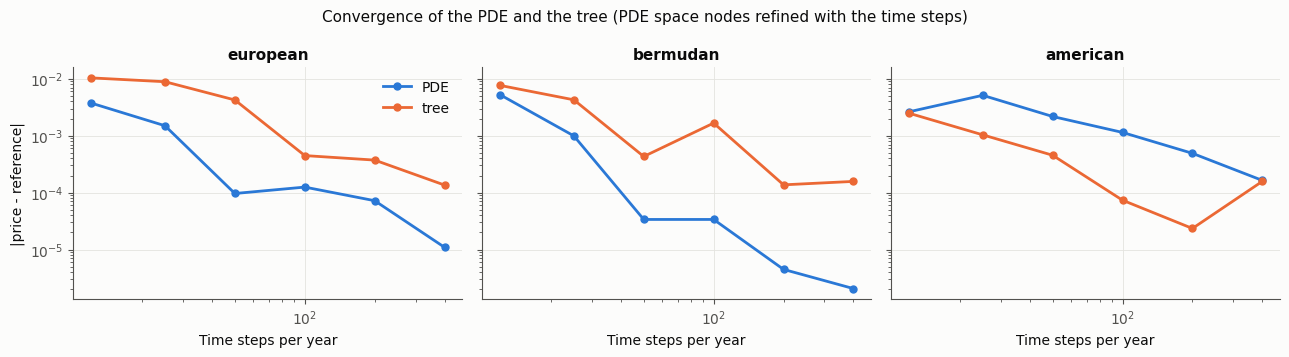

error (cents per 100)      PDE                       tree                  
style                 american bermudan european american bermudan european
steps / year                                                               
12                      0.2623   0.5281   0.3754   0.2496   0.7668   1.0378
25                      0.5126   0.0994   0.1498   0.1036    0.427   0.8878
50                      0.2178   0.0034   0.0097   0.0454   0.0432   0.4246
100                     0.1143   0.0034   0.0125   0.0074   0.1668   0.0448
200                     0.0491   0.0004   0.0072   0.0024   0.0137   0.0373
400                     0.0164   0.0002   0.0011   0.0158   0.0158   0.0136

In [12]:
reference = CallableBondPDE(hw, credit, RECOVERY, n_x=3201, steps_per_year=800)
ref = {style: reference.price(b) for style, b in bonds.items()}
rows = []
for spy, n_x in [(12, 51), (25, 101), (50, 201), (100, 401), (200, 801), (400, 1601)]:
    p, tr = CallableBondPDE(hw, credit, RECOVERY, n_x=n_x, steps_per_year=spy), CallableBondTree(hw, credit, RECOVERY, steps_per_year=spy)
    for style, b in bonds.items():
        rows.append({"steps / year": spy, "style": style, "PDE": abs(p.price(b) - ref[style]),
                     "tree": abs(tr.price(b) - ref[style])})
conv = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, style in zip(axes, EXERCISE_STYLES):
    c = conv[conv["style"] == style]
    for method in ["PDE", "tree"]:
        ax.loglog(c["steps / year"], np.maximum(c[method], 1e-8), "o-", ms=5, color=METHOD_COLOR[method], label=method)
    ax.set_title(style); ax.set_xlabel("Time steps per year")
axes[0].set_ylabel("|price - reference|"); axes[0].legend()
fig.suptitle("Convergence of the PDE and the tree (PDE space nodes refined with the time steps)", fontsize=11)
plt.tight_layout(); plt.show()
conv.pivot(index="steps / year", columns="style", values=["PDE", "tree"]).mul(100).round(4).rename_axis(
    columns=["error (cents per 100)", "style"])

## 4. Market measures from a quoted price

The bond is observed in the market at a **clean** price; the pricer turns it into spreads and yields.

- **Z-spread**: constant spread over the risk-free short rate that reprices the bond *ignoring the call*.
- **OAS**: the same spread *with* the call, valued in the calibrated Hull-White model. OAS < Z-spread: part of the
  extra yield pays for the short option, not for credit.
- **Yield to worst**: the lowest of the yield to maturity and the yields to each call date (redeemed at
  call price + accrued). For a bond **above par** the worst case is an early call.

In [13]:
QUOTE = 98.50                                                       # clean price, ILLUSTRATIVE
reports = {style: pricing_report(pde, b, market_price=QUOTE) for style, b in bonds.items()}
pd.DataFrame(reports)

,european,bermudan,american
dirty price,98.7382,98.205,98.089
accrued interest,1.45753,1.45753,1.45753
clean price,97.2807,96.7475,96.6314
straight bond (dirty),99.9402,99.9402,99.9402
call option (issuer),1.20203,1.73521,1.85128
Z-spread (bp),138.728,138.728,138.728
OAS (bp),106.327,92.765,89.86
yield to maturity (%),4.94107,4.94107,4.94107
yield to worst (%),4.94107,4.94107,4.94107
effective duration,6.04428,5.9272,5.89372


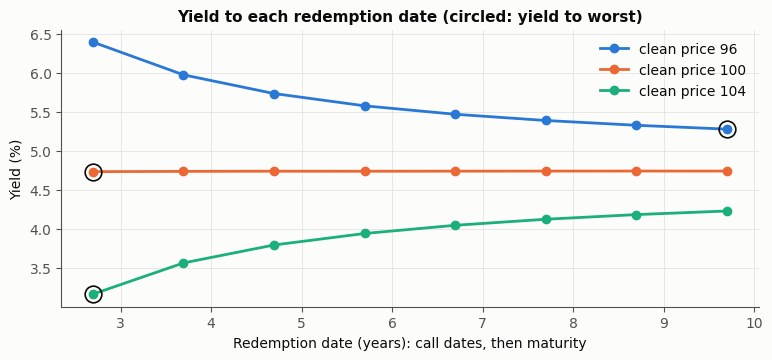

,t,redemption,yield (%),worst
date,,,,
2029-06-15,2.69589,100,3.16754,<-
2030-06-15,3.69589,100,3.5668,
2031-06-15,4.69589,100,3.79659,
2032-06-15,5.69863,100,3.94406,
2033-06-15,6.69863,100,4.04884,
2034-06-15,7.69863,100,4.1263,
2035-06-15,8.69863,100,4.18584,
2036-06-15,9.70137,100,4.232,


In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for clean, color, ls in [(96.0, COLORS[0], "-"), (100.0, COLORS[1], "-"), (104.0, COLORS[2], "-")]:
    yt = yield_table(berm, clean + bond.accrued_today)
    ax.plot(yt["t"], yt["yield (%)"], "o" + ls, ms=6, color=color, label=f"clean price {clean:g}")
    worst = yt["yield (%)"].idxmin()
    ax.plot(yt["t"][worst], yt["yield (%)"][worst], "o", ms=12, mfc="none", mec=INK, mew=1.2)
ax.set_xlabel("Redemption date (years): call dates, then maturity"); ax.set_ylabel("Yield (%)")
ax.set_title("Yield to each redemption date (circled: yield to worst)"); ax.legend(); plt.show()
yield_table(berm, 104.0 + bond.accrued_today).assign(date=lambda d: bond.date_of(d["t"]).date).set_index("date")

## 5. Risk

### 5.1 Effective duration, convexity, vega and CS01, by method
Parallel shifts of the risk-free curve ($\pm 10$bp), Hull-White refitted to each shifted curve ($a$, $\sigma$
unchanged); vega per 1bp of $\sigma$; CS01 per 1bp of hazard rate. Longstaff-Schwartz uses common random numbers
across bumps.

In [15]:
rows = []
for name in ["PDE", "tree", "LSM"]:
    for style in ["straight", "european", "bermudan"]:
        b, callable_ = (bond, False) if style == "straight" else (bonds[style], True)
        rows.append({"method": name, "bond": style, **effective_risk(pricers[name], b, callable=callable_)})
    if name != "LSM":
        rows.append({"method": name, "bond": "american", **effective_risk(pricers[name], bonds["american"])})
risk = pd.DataFrame(rows).set_index(["bond", "method"]).sort_index(level=0, key=lambda i: i.map(
    {"straight": 0, "european": 1, "bermudan": 2, "american": 3}))
risk

price  effective duration  effective convexity      DV01  \
bond     method                                                              
straight LSM    99.9512             7.55981              66.5173 0.0755612   
         PDE    99.9402             7.55962              66.5149  0.075551   
         tree   99.9402             7.55962              66.5149  0.075551   
european LSM    98.7149             5.99114             -87.5935 0.0591414   
         PDE    98.7382             6.04428             -91.9977 0.0596801   
         tree   98.7388              6.0387             -137.362 0.0596254   
bermudan LSM    98.1854             5.91986             -110.153 0.0581244   
         PDE     98.205              5.9272             -69.8885 0.0582081   
         tree   98.2034             5.92553             -60.2004 0.0581907   
american PDE     98.089             5.89372             -70.5979 0.0578109   
         tree   98.0877             5.89429             -78.9219 0.0578158   

                 vega (per bp of sigma)       CS01  
bond     method                                     
straight LSM                0.000197191 -0.0451103  
         PDE                1.01044e-08 -0.0451013  
         tree              -6.22393e-10 -0.0451013  
european LSM                  -0.021022 -0.0356888  
         PDE                 -0.0198942 -0.0352396  
         tree                -0.0194195 -0.0357713  
bermudan LSM                 -0.0270437 -0.0352156  
         PDE                 -0.0271022 -0.0341596  
         tree                -0.0271931 -0.0341768  
american PDE                  -0.028469  -0.033946  
         tree                -0.0285666 -0.0338798

The three methods agree on duration, DV01, vega and CS01. Effective convexity is a second difference
($\pm 10$bp), sensitive to the discrete exercise: smooth for the PDE, noisier for the tree (the call snaps to
nodes) and for Monte Carlo (the policy is re-estimated in each scenario). Read it from the PDE.

The straight bond has a positive convexity; the callable bonds have a **negative** convexity and a shorter
duration: when rates fall the call gets closer and the expected life shortens. Vega is negative: the bondholder is
short the issuer's option. The CS01 of callable bonds is smaller: a wider spread pushes the call out of the money.

### 5.2 Key-rate durations
Triangular shifts of each pillar (Ho 1992); they add up to the effective duration. The straight bond's risk sits on
the 9-10 year pillars; the call **moves risk to the call dates**: the callable bond behaves partly like a bond
maturing at the first call.

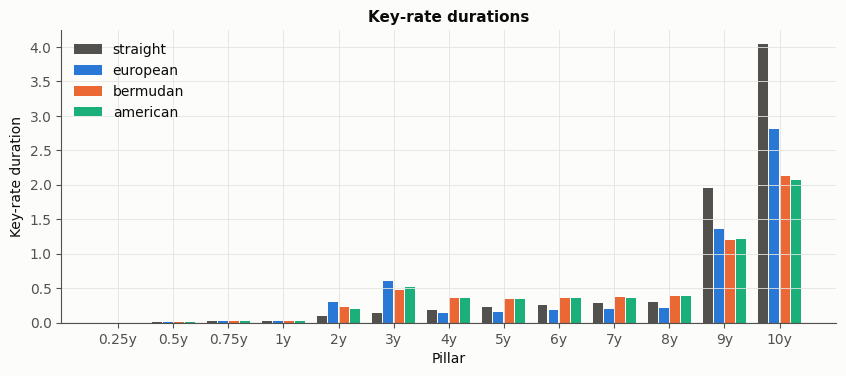

,sum of key-rate durations,effective duration (1bp)
straight,7.55952,7.55952
european,6.04294,6.04294
bermudan,5.92049,5.92005
american,5.89956,5.89535


In [16]:
krd = {"straight": key_rate_durations(pde, bond, callable=False),
       **{style: key_rate_durations(pde, b) for style, b in bonds.items()}}
krd = pd.DataFrame(krd)
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.2
for i, name in enumerate(krd.columns):
    ax.bar(np.arange(len(krd)) + (i - 1.5) * width, krd[name], width * 0.9, color=STYLE_COLOR[name], label=name)
ax.set_xticks(np.arange(len(krd))); ax.set_xticklabels([f"{t:g}y" for t in krd.index])
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Pillar"); ax.set_ylabel("Key-rate duration"); ax.set_title("Key-rate durations"); ax.legend()
plt.show()
check = pd.DataFrame({"sum of key-rate durations": krd.sum(),
                      "effective duration (1bp)": [effective_risk(pde, b, bp=1.0, callable=c)["effective duration"]
                                                   for b, c in [(bond, False)] + [(bonds[s], True) for s in EXERCISE_STYLES]]})
check

### 5.3 Price profile: negative convexity
The PDE gives $V(0, x)$ for every initial short rate at once. When rates fall the straight bond keeps rising,
the callable bond is capped near the call price; the American cap binds first. On the right, full repricing under
parallel shifts of the curve.

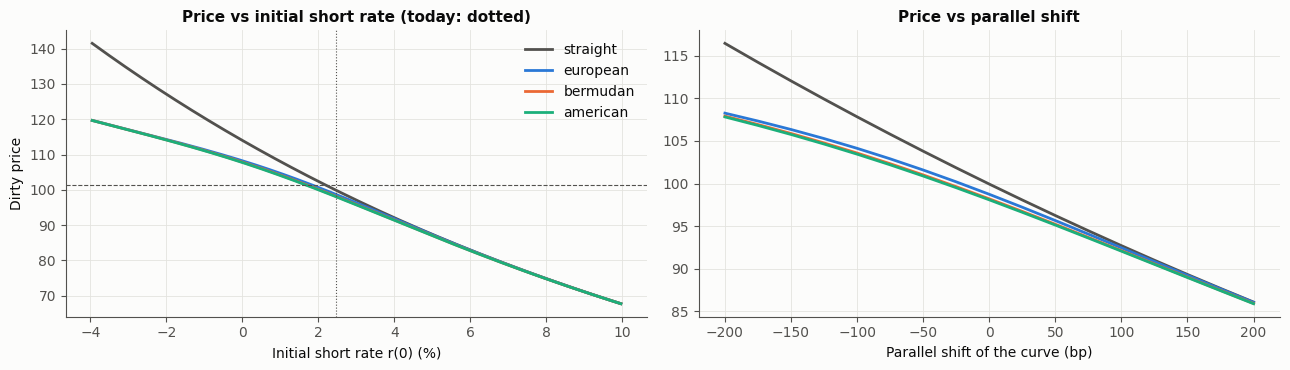

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sol = pde.solve(bond, callable=False)
mask = (sol["short rate"] > -0.04) & (sol["short rate"] < 0.10)
axes[0].plot(100 * sol["short rate"][mask], sol["values"][mask], color=STYLE_COLOR["straight"], label="straight")
for style, b in bonds.items():
    s = pde.solve(b)
    axes[0].plot(100 * s["short rate"][mask], s["values"][mask], color=STYLE_COLOR[style], label=style)
axes[0].axhline(100 + bond.accrued_today, color=MUTED, lw=0.8, ls="--")
axes[0].axvline(100 * sol["short rate"][pde.n_x // 2], color=MUTED, lw=0.8, ls=":")
axes[0].set_xlabel("Initial short rate r(0) (%)"); axes[0].set_ylabel("Dirty price")
axes[0].set_title("Price vs initial short rate (today: dotted)"); axes[0].legend()

shifts = np.arange(-200, 201, 25)
scenario = {name: [] for name in ["straight", *EXERCISE_STYLES]}
for bp in shifts:
    p = pde.with_model(hw.with_curve(curve.shifted(bp)))
    scenario["straight"].append(p.price(bond, callable=False))
    for style, b in bonds.items():
        scenario[style].append(p.price(b))
for name, values in scenario.items():
    axes[1].plot(shifts, values, color=STYLE_COLOR[name], label=name)
axes[1].set_xlabel("Parallel shift of the curve (bp)"); axes[1].set_title("Price vs parallel shift")
plt.tight_layout(); plt.show()

## 6. When does the issuer call?

### 6.1 Exercise boundary
The issuer calls when rates are **low**: below a critical short rate $r^*(t)$ the bond is worth more than the
call price. For the American bond $r^*(t)$ is a continuous boundary, rising toward maturity (fewer coupons left to
save). With more future call dates the issuer waits for lower rates: European threshold > Bermudan > American.

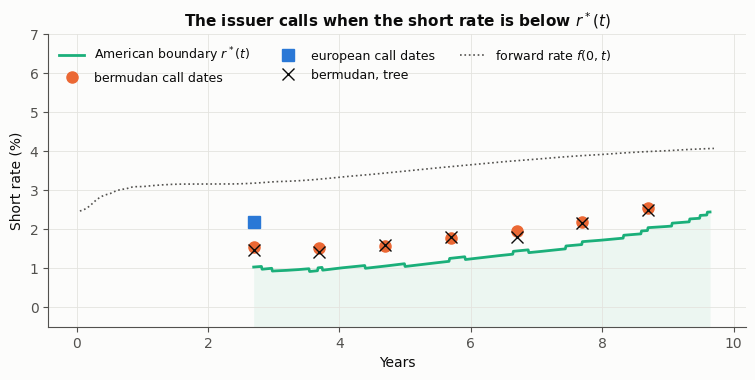

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
t_am, r_am = pde.short_rate_boundary(bonds["american"])
keep = t_am < bond.maturity - 0.05                         # last days : called almost surely, grid edge
t_am, r_am = t_am[keep], r_am[keep]
ax.plot(t_am, 100 * r_am, color=STYLE_COLOR["american"], label="American boundary $r^*(t)$")
for style, marker in [("bermudan", "o"), ("european", "s")]:
    t_b, r_b = pde.short_rate_boundary(bonds[style])
    ax.plot(t_b, 100 * r_b, marker, color=STYLE_COLOR[style], ms=8, label=f"{style} call dates")
t_tr, r_tr = tree.short_rate_boundary(bonds["bermudan"])
ax.plot(t_tr, 100 * r_tr, "x", color=INK, ms=8, label="bermudan, tree")
tt = np.linspace(0.05, bond.maturity, 400)
ax.plot(tt, 100 * curve.instantaneous_forward(tt), ":", color=MUTED, lw=1.2, label="forward rate $f(0,t)$")
ax.fill_between(t_am, -1, 100 * r_am, color=STYLE_COLOR["american"], alpha=0.07, lw=0)
ax.set_ylim(min(-0.5, 100 * np.nanmin(r_am) - 0.5), 7)
ax.set_xlabel("Years"); ax.set_ylabel("Short rate (%)")
ax.set_title("The issuer calls when the short rate is below $r^*(t)$"); ax.legend(loc="upper left", ncol=3, fontsize=9)
plt.show()

### 6.2 Call probabilities and expected life
From the Longstaff-Schwartz paths (given survival): probability that the bond is called on each date (left,
discrete styles), share of the bonds still outstanding over time (right, all styles: the American is called on
monthly dates), total probability of a call and expected life (call date, or maturity if never called).
Most Bermudan calls happen on the first call date; the American issuer spreads them over the whole call period,
waiting for lower rates, so it calls more often in total but not earlier on average.

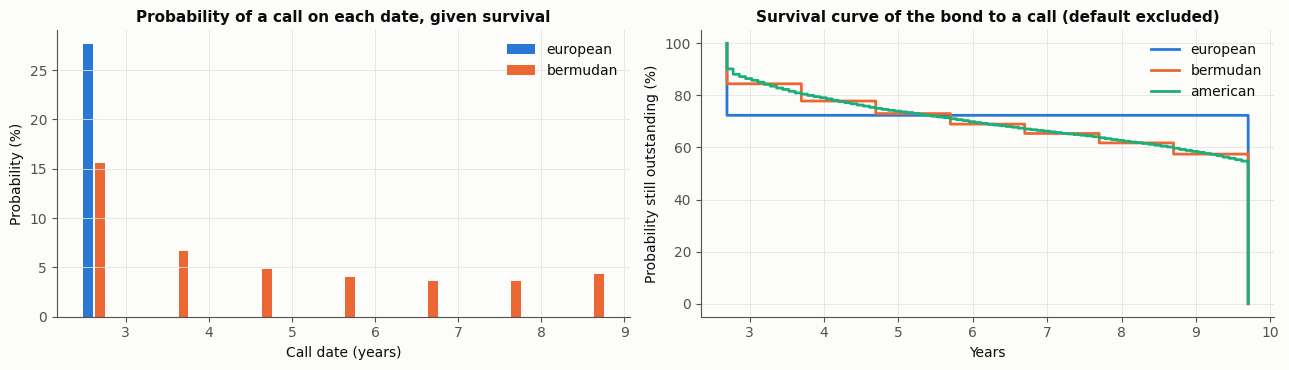

,probability of a call (%),expected life (years),maturity (years)
european,27.64,7.76506,9.70137
bermudan,42.544,7.58869,9.70137
american,45.606,7.60014,9.70137


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for style, w, off in [("european", 0.12, -0.15), ("bermudan", 0.12, 0.0)]:
    pr = lsm_results[style]["call probability"]
    axes[0].bar(np.array(list(pr)) + off, 100 * np.array(list(pr.values())), w, color=STYLE_COLOR[style], label=style)
axes[0].set_xlabel("Call date (years)"); axes[0].set_ylabel("Probability (%)")
axes[0].set_title("Probability of a call on each date, given survival"); axes[0].legend()

for style in EXERCISE_STYLES:
    life = np.sort(lsm_results[style]["life"])
    axes[1].plot(life, 100 * (1 - np.arange(1, len(life) + 1) / len(life)), color=STYLE_COLOR[style], label=style,
                 drawstyle="steps-post")
axes[1].set_xlabel("Years"); axes[1].set_ylabel("Probability still outstanding (%)")
axes[1].set_title("Survival curve of the bond to a call (default excluded)"); axes[1].legend()
plt.tight_layout(); plt.show()

pd.DataFrame({style: {"probability of a call (%)": 100 * r["probability called"],
                      "expected life (years)": r["expected life"],
                      "maturity (years)": bond.maturity} for style, r in lsm_results.items() if style != "straight"}).T

## 7. Model risk

### 7.1 Mean reversion at fixed calibration
For each mean reversion $a$, $\sigma$ is recalibrated to the same co-terminal swaptions. The **European** price
barely moves (it is a co-terminal swaption, close to the calibration set). The **Bermudan and American** prices
depend on $a$: it sets the correlation between rates at different call dates, i.e. the value of the switch
option, which European swaptions do not see.

In [20]:
rows = []
for a in [0.005, 0.02, 0.05, hw.a, 0.15, 0.25]:
    model = HullWhite(curve, a=a)
    fit = model.calibrate(market, swaptions, fixed={"a": a})
    p = pde.with_model(model)
    rows.append({"a": a, "sigma (bp)": 1e4 * model.sigma, "calibration RMSE (bp)": fit["RMSE (bp of normal vol)"],
                 **{style: p.price(b) for style, b in bonds.items()}})
mr = pd.DataFrame(rows).set_index("a")
for style in EXERCISE_STYLES:
    mr[f"{style} - calibrated"] = mr[style] - pde.price(bonds[style])
mr

,sigma (bp),calibration RMSE (bp),european,bermudan,american,european - calibrated,bermudan - calibrated,american - calibrated
a,,,,,,,,
0.005,77.9112,0.926866,98.7518,98.3466,98.2709,0.0135906,0.14155,0.18195
0.02,83.5295,0.879299,98.7489,98.3218,98.2396,0.0106473,0.1168,0.150677
0.05,95.6414,0.802115,98.7435,98.2704,98.1739,0.00524212,0.0653413,0.0849406
0.0863376,111.922,0.762421,98.7382,98.205,98.089,-1.88223e-09,-2.56207e-09,-2.69124e-09
0.15,144.839,0.906949,98.7325,98.0838,97.9266,-0.00572861,-0.121262,-0.162306
0.25,208.061,1.57969,98.7311,97.8813,97.644,-0.0071455,-0.323743,-0.444933


### 7.2 Volatility and credit
The issuer's option increases with $\sigma$. A credit deterioration lowers the bond, pushes it further below the
call price and makes the call less valuable.

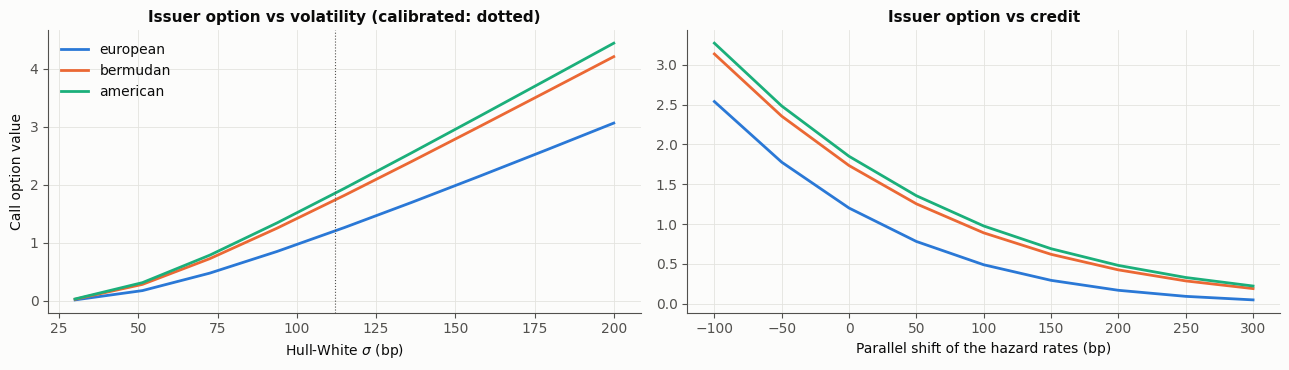

In [21]:
sigmas = np.linspace(0.003, 0.020, 9)
hazard_shifts = np.arange(-100, 301, 50)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for style, b in bonds.items():
    axes[0].plot(1e4 * sigmas, [straight_dirty - pde.with_model(hw.with_vol_shift(s - hw.sigma)).price(b) for s in sigmas],
                 color=STYLE_COLOR[style], label=style)
    axes[1].plot(hazard_shifts, [pde.with_credit(credit.shifted(bp)).price(bond, callable=False)
                                 - pde.with_credit(credit.shifted(bp)).price(b) for bp in hazard_shifts],
                 color=STYLE_COLOR[style], label=style)
axes[0].axvline(1e4 * hw.sigma, color=MUTED, lw=0.8, ls=":")
axes[0].set_xlabel(r"Hull-White $\sigma$ (bp)"); axes[0].set_ylabel("Call option value"); axes[0].legend()
axes[0].set_title("Issuer option vs volatility (calibrated: dotted)")
axes[1].set_xlabel("Parallel shift of the hazard rates (bp)"); axes[1].set_title("Issuer option vs credit")
plt.tight_layout(); plt.show()

## 8. Term sheet variants

The pricer takes any call schedule, call frequency and coupon frequency. Three common variants of the same bond:

- **step-down call price**: 102 from 2029, 101 from 2031, par from 2033 (the premium makes early calls costly);
- **semi-annual coupons** (same annual rate, Bermudan calls on every coupon date);
- **quarterly Bermudan calls** on an annual-coupon bond (accrued interest added to the call price between coupons).

In [22]:
variants = {
    "base (par call)": bond,
    "step-down 102 / 101 / 100": DatedCallableBond(VALUATION, "2036-06-15", 0.0475, "2029-06-15", issue_date="2024-06-15",
                                                   call_schedule={"2029-06-15": 102, "2031-06-15": 101, "2033-06-15": 100}),
    "semi-annual coupons": DatedCallableBond(VALUATION, "2036-06-15", 0.0475, "2029-06-15", frequency=2,
                                             issue_date="2024-06-15"),
    "quarterly calls": DatedCallableBond(VALUATION, "2036-06-15", 0.0475, "2029-06-15", issue_date="2024-06-15",
                                         call_frequency=4),
}
rows = []
for name, v in variants.items():
    straight_v = pde.price(v, callable=False)
    for style in (["bermudan"] if name == "quarterly calls" else EXERCISE_STYLES):
        b = v.with_exercise(style)
        price = pde.price(b)
        rows.append({"variant": name, "style": style, "accrued": v.accrued_today, "dirty": price,
                     "clean": price - v.accrued_today, "call option": straight_v - price,
                     "tree - PDE": tree.price(b) - price})
pd.DataFrame(rows).set_index(["variant", "style"])

accrued   dirty   clean  call option  \
variant                   style                                            
base (par call)           european  1.45753 98.7382 97.2807      1.20203   
                          bermudan  1.45753  98.205 96.7475      1.73521   
                          american  1.45753  98.089 96.6314      1.85128   
step-down 102 / 101 / 100 european  1.45753 99.1624 97.7048     0.777874   
                          bermudan  1.45753  98.597 97.1394      1.34328   
                          american  1.45753 98.5088 97.0513      1.43139   
semi-annual coupons       european  1.45355 99.1783 97.7247      1.29443   
                          bermudan  1.45355 98.5841 97.1306      1.88859   
                          american  1.45355 98.5235 97.0699      1.94926   
quarterly calls           bermudan  1.45753 98.1196  96.662      1.82069   

                                    tree - PDE  
variant                   style                 
base (par call)           european 0.000573345  
                          bermudan -0.00163439  
                          american -0.00121652  
step-down 102 / 101 / 100 european -0.00141223  
                          bermudan -0.00117553  
                          american  -0.0012229  
semi-annual coupons       european -0.00198292  
                          bermudan -0.00128246  
                          american -0.00179634  
quarterly calls           bermudan -0.00170499

## 9. Summary and limitations

- **One model, three styles, three methods.** The PDE, the trinomial tree and Longstaff-Schwartz agree on every
  style, reprice the straight bond and the European call in closed form (Jamshidian, with and without default),
  and the Bermudan converges to the American as the call dates get denser.
- **Production choice.** The PDE is the fastest and gives the smoothest Greeks; the tree is a transparent check;
  Monte Carlo is the only one that extends to several factors and gives call probabilities and life per path.
- **Market measures.** From a quoted clean price: OAS, Z-spread, yield to worst; risk as effective duration,
  negative convexity, key-rate durations concentrated on the call dates, negative vega.
- **Limitations.** One rate factor cannot decorrelate rates of different maturities (a Bermudan/American price
  depends on the mean reversion, §7.1). Default intensity is deterministic and independent of rates, so the issuer
  does not call when its own spread tightens. No calendar adjustment, settlement lag or call notice period; the
  LSM American uses monthly calls. Swaption volatilities, CDS spreads and the term sheet are illustrative.